### Feature (X) and Target (y) setup

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import sqlite3


#### Goal:
- To predict whether a team will win or lose depending on the box score of their team on that specific game

In [98]:
conn = sqlite3.connect("boxscore_ai.db")
df = pd.read_sql("SELECT * FROM games", conn)
conn.close
df.head()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
0,22400062,1610612750,22024,2024-10-22,MIN,MIN @ LAL,L,103,17,4,...,35,85,0.412,13,41,20,27,12,35,47
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,...,42,95,0.442,5,30,21,25,15,31,46
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,...,48,95,0.505,29,61,7,8,11,29,40
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,...,43,78,0.551,11,30,12,16,5,29,34
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,...,41,96,0.427,18,49,16,22,18,39,57


In [99]:
df_copy = df.copy()
df_copy.head

<bound method NDFrame.head of        GAME_ID     TEAM_ID  SEASON_ID   GAME_DATE TEAM_ABBREVIATION  \
0     22400062  1610612750      22024  2024-10-22               MIN   
1     22400062  1610612747      22024  2024-10-22               LAL   
2     22400061  1610612738      22024  2024-10-22               BOS   
3     22400061  1610612752      22024  2024-10-22               NYK   
4     22400065  1610612753      22024  2024-10-23               ORL   
...        ...         ...        ...         ...               ...   
2455  22401195  1610612750      22024  2025-04-13               MIN   
2456  22401194  1610612742      22024  2025-04-13               DAL   
2457  22401190  1610612748      22024  2025-04-13               MIA   
2458  22401192  1610612749      22024  2025-04-13               MIL   
2459  22401187  1610612738      22024  2025-04-13               BOS   

          MATCHUP WL  PTS  AST  STL  ...  FGM  FGA  FG_PCT  FG3M  FG3A  FTM  \
0       MIN @ LAL  L  103   17    4  .

In [ ]:
df_copy.sort_values(by=["GAME_DATE"])

stats = ["PTS", "FG_PCT", "AST", "REB"]

# models will predict the outcome of the upcoming game based on the last 5 games performace of a team
for col in stats:
    df_copy[f"{col}_last_5_games_avg"] = (
        df_copy.groupby("TEAM_ID")[col]
        .shift(1)
        .rolling(5)
        .mean()
    )

df_copy.head()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FG3A,FTM,FTA,OREB,DREB,REB,PTS_last_5_games_avg,FG_PCT_last_5_games_avg,AST_last_5_games_avg,REB_last_5_games_avg
0,22400062,1610612750,22024,2024-10-22,MIN,MIN @ LAL,L,103,17,4,...,41,20,27,12,35,47,NaN,NaN,NaN,NaN
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,...,30,21,25,15,31,46,NaN,NaN,NaN,NaN
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,...,61,7,8,11,29,40,NaN,NaN,NaN,NaN
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,...,30,12,16,5,29,34,NaN,NaN,NaN,NaN
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,...,49,16,22,18,39,57,NaN,NaN,NaN,NaN


In [107]:
#  rows starting from Game 6 onwards
df_copy = df_copy.dropna()

In [108]:
df_copy.dropna()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FG3A,FTM,FTA,OREB,DREB,REB,PTS_last_5_games_avg,FG_PCT_last_5_games_avg,AST_last_5_games_avg,REB_last_5_games_avg
35,22400081,1610612754,22024,2024-10-25,IND,IND @ NYK,L,98,28,8,...,30,13,20,9,24,33,118.0,0.4826,28.8,45.0
36,22400077,1610612751,22024,2024-10-25,BKN,BKN @ ORL,L,101,22,7,...,37,17,21,8,29,37,114.8,0.4696,26.4,45.6
37,22400081,1610612752,22024,2024-10-25,NYK,NYK vs. IND,W,123,19,5,...,27,23,29,11,32,43,113.4,0.4824,25.4,44.0
38,22400078,1610612761,22024,2024-10-25,TOR,TOR vs. PHI,W,115,25,11,...,23,39,46,18,36,54,112.4,0.4686,25.2,42.2
39,22400085,1610612747,22024,2024-10-25,LAL,LAL vs. PHX,W,123,33,10,...,27,29,39,6,31,37,111.2,0.4716,24.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2455,22401195,1610612750,22024,2025-04-13,MIN,MIN vs. UTA,W,116,23,9,...,43,11,16,17,37,54,107.8,0.4520,28.0,45.4
2456,22401194,1610612742,22024,2025-04-13,DAL,DAL @ MEM,L,97,20,6,...,28,16,22,10,28,38,109.2,0.4654,28.4,46.2
2457,22401190,1610612748,22024,2025-04-13,MIA,MIA vs. WAS,L,118,28,8,...,32,10,12,9,37,46,119.2,0.4974,30.4,49.2
2458,22401192,1610612749,22024,2025-04-13,MIL,MIL vs. DET,W,140,30,5,...,44,17,22,6,32,38,123.4,0.5088,31.0,49.6


In [109]:
# NOTE: Top stats based on EDA: AST, REB, OREB
X = df_copy[["PTS_last_5_games_avg", "FG_PCT_last_5_games_avg", "AST_last_5_games_avg", "REB_last_5_games_avg"]].values    # features
y = df_copy["WL"] # target

In [110]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3 , random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) # trains and scales data
X_test = scaler.transform(X_test)   # uses the trained data and compare to tests to evaluate 

In [111]:
log_reg = LogisticRegression()
clf = RandomForestClassifier(n_estimators=100, random_state=42)

In [112]:
log_reg.fit(X_train, y_train)
clf.fit(X_train, y_train)

y1_pred = log_reg.predict(X_test)
y2_pred = clf.predict(X_test)

print("Classification report of Logistic Regression")
print(classification_report(y_test, y1_pred))


print("Classification report of Random Forest Classifier")
print(classification_report(y_test, y2_pred))

Classification report of Logistic Regression
              precision    recall  f1-score   support

           L       0.52      0.50      0.51       364
           W       0.52      0.53      0.52       364

    accuracy                           0.52       728
   macro avg       0.52      0.52      0.52       728
weighted avg       0.52      0.52      0.52       728

Classification report of Random Forest Classifier
              precision    recall  f1-score   support

           L       0.50      0.56      0.53       364
           W       0.50      0.44      0.47       364

    accuracy                           0.50       728
   macro avg       0.50      0.50      0.50       728
weighted avg       0.50      0.50      0.50       728



- Logisitic Regression is slightly more accurate than Random Forest Classifier when it comes to predicting the Wins of teams based on their PTS, FG_PCT, AST, and REB from their last 5 games.

In [113]:
conf_matrix1 = confusion_matrix(y_test, y1_pred)
conf_matrix2 = confusion_matrix(y_test, y2_pred)

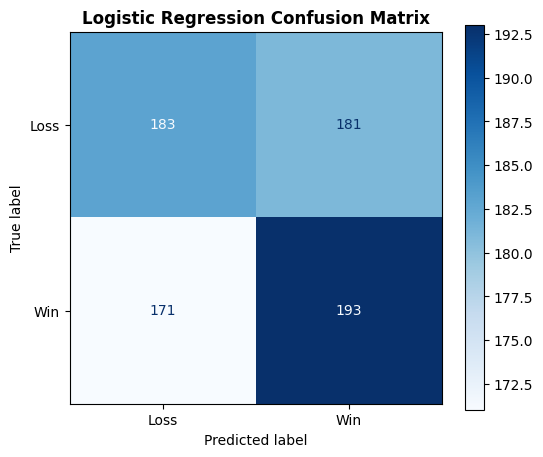

In [114]:
# Logistic Regression confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm_display1 = metrics.ConfusionMatrixDisplay(confusion_matrix = conf_matrix1, display_labels=['Loss', 'Win'])

cm_display1.plot(cmap='Blues', ax=ax)
ax.set_title("Logistic Regression Confusion Matrix", fontsize=12, fontweight="bold")
plt.show()

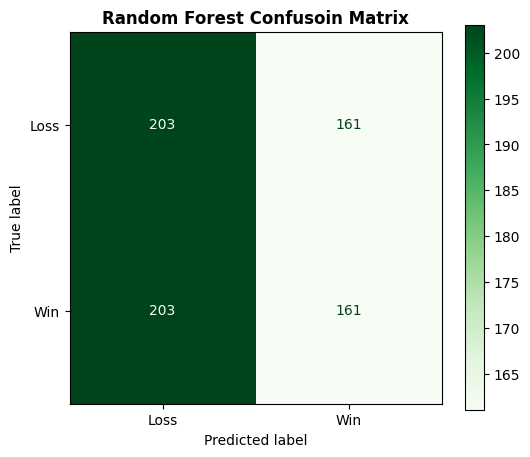

In [115]:
# Random Forest Confusion Matrix Plot
fig, ax = plt.subplots(figsize=(6, 5))
cm_display2 = metrics.ConfusionMatrixDisplay(confusion_matrix = conf_matrix2, display_labels=['Loss', 'Win'])

cm_display2.plot(cmap="Greens", ax=ax)
ax.set_title("Random Forest Confusoin Matrix", fontsize=12, fontweight="bold")
plt.show()

#### Observation:

- The logistic regression correctly predicted the true positive and true negatives with a total of 376 correct predictions.
- 181 False Positives and 171 False Negatives which is still a bit high because this time we're predicting the outcomes of an upcoming game based on the last 5 games (before, we didn't based on this so we predict the outcome of the game based on the outcome stats which makes it easer for models to predict more accurately) 
- While the random forest classifier has slightly fewer correct predictions with a total of 364 identified true positives and true negaticves. 
- 161 False Positives which is a bit lower than logisitc regression but it 203 False Negatives which shows less accuracy of this model.